# 02 - Time Series Analysis

## Objective

Analyse historical agricultural market prices across 46 selected vegetable commodities in India to evaluate market-level reporting patterns, historical coverage, reporting continuity, price behaviour, seasonality and suitability for forecasting.

This notebook aims to:

1. Examine the structure and completeness of the expanded vegetable dataset.
2. Understand daily reporting patterns across commodities and agricultural markets.
3. Investigate the influence of varieties and grades on observed prices.
4. Measure historical coverage and reporting continuity of individual market-level price series.
5. Identify reporting interruptions and assess data recency.
6. Analyse price behaviour, volatility and seasonal patterns.
7. Establish evidence-based criteria for selecting series for retrospective forecasting experiments.

## Input

`data/processed/vegetables_prices_cleaned.parquet`

## Output

A documented assessment of historical time-series suitability across all 46 selected vegetables, supporting forecasting-series selection and subsequent model development.

## Important limitation

The dataset contains historical records from 10 January 2001 to 20 April 2026. Reporting activity declines substantially from November 2025 onward. Historical forecasting experiments may be feasible, but this dataset does not establish that selected series are suitable for current market predictions.

In [5]:
from pathlib import Path

import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project paths
ROOT = Path.cwd().parent
PROCESSED_DIR = ROOT / "data" / "processed"

# Expanded 46-vegetable dataset
DATA_FILE = PROCESSED_DIR / "vegetable_prices_cleaned.parquet"

# Verify project paths
print("Project root:", ROOT)
print("Processed directory exists:", PROCESSED_DIR.exists())
print("Dataset file:", DATA_FILE)
print("Dataset exists:", DATA_FILE.exists())

Project root: c:\Users\Lenovo\Documents\GrittingCode\MandiMitra
Processed directory exists: True
Dataset file: c:\Users\Lenovo\Documents\GrittingCode\MandiMitra\data\processed\vegetable_prices_cleaned.parquet
Dataset exists: True


In [6]:
# Create DuckDB connection
con = duckdb.connect()

# Load the cleaned vegetable dataset as a view
con.execute(f"""
    CREATE OR REPLACE VIEW prices AS
    SELECT *
    FROM read_parquet('{DATA_FILE.as_posix()}')
""")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [7]:
# Inspect dataset schema
schema = con.execute("""
    DESCRIBE prices
""").df()

display(schema)

,column_name,column_type,null,key,default,extra
0,State,VARCHAR,YES,None,None,None
1,District,VARCHAR,YES,None,None,None
2,Market,VARCHAR,YES,None,None,None
3,Source_Commodity,VARCHAR,YES,None,None,None
4,Project_Commodity,VARCHAR,YES,None,None,None
5,Variety,VARCHAR,YES,None,None,None
6,Grade,VARCHAR,YES,None,None,None
7,Arrival_Date,VARCHAR,YES,None,None,None
8,Parsed_Date,DATE,YES,None,None,None
9,Min_Price,DOUBLE,YES,None,None,None


In [8]:
dataset_overview = con.execute("""
    SELECT
        COUNT(*) AS Total_Records,

        COUNT(DISTINCT Project_Commodity)
            AS Total_Commodities,

        COUNT(DISTINCT State)
            AS Total_States,

        COUNT(DISTINCT District)
            AS Total_Districts,

        COUNT(DISTINCT (State, District, Market))
            AS Total_Markets,

        COUNT(DISTINCT Variety)
            AS Total_Varieties,

        COUNT(DISTINCT Grade)
            AS Total_Grades,

        MIN(Parsed_Date) AS First_Date,

        MAX(Parsed_Date) AS Last_Date,

        COUNT(*) FILTER (
            WHERE is_forecast_eligible
        ) AS Forecast_Eligible_Records

    FROM prices
""").df()

display(dataset_overview)

,Total_Records,Total_Commodities,Total_States,Total_Districts,Total_Markets,Total_Varieties,Total_Grades,First_Date,Last_Date,Forecast_Eligible_Records
0,30336319,46,33,616,4550,137,14,2001-01-10,2026-04-20,30336319


In [9]:
commodity_overview = con.execute("""
    SELECT
        Project_Commodity,

        COUNT(*) AS Total_Records,

        COUNT(DISTINCT State) AS States,

        COUNT(DISTINCT (State, District, Market))
            AS Markets,

        COUNT(DISTINCT (Variety, Grade))
            AS Variety_Grade_Combinations,

        MIN(Parsed_Date) AS First_Date,

        MAX(Parsed_Date) AS Last_Date,

        COUNT(DISTINCT Parsed_Date)
            AS Overall_Reporting_Days,

        ROUND(AVG(Modal_Price), 2)
            AS Average_Modal_Price,

        MEDIAN(Modal_Price)
            AS Median_Modal_Price

    FROM prices

    GROUP BY Project_Commodity

    ORDER BY Total_Records DESC
""").df()

display(commodity_overview)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Project_Commodity,Total_Records,States,Markets,Variety_Grade_Combinations,First_Date,Last_Date,Overall_Reporting_Days,Average_Modal_Price,Median_Modal_Price
0,Potato,3248774,33,2990,130,2001-01-10,2026-04-20,9096,1193.17,925.0
1,Onion,3168401,32,3223,178,2001-01-10,2026-04-20,9101,2050.86,1400.0
2,Tomato,2818498,32,3075,62,2001-02-08,2026-04-20,9072,1767.50,1400.0
3,Brinjal,2448357,31,2897,67,2001-01-27,2026-04-20,9071,1702.14,1330.0
4,Green Chilli,2107918,31,2834,23,2001-03-12,2026-04-20,9019,2999.39,2465.0
5,Cauliflower,1701542,33,2397,55,2001-01-27,2026-04-20,9068,1733.64,1300.0
6,Bhindi (Ladies Finger),1571994,31,2493,23,2001-04-08,2026-04-20,9008,2366.99,2000.0
7,Cabbage,1505826,33,2572,23,2001-11-22,2026-04-20,8866,1396.35,1000.0
8,Bottle gourd,1214983,31,2083,26,2001-04-12,2026-04-20,8981,1248.91,1050.0
9,Bitter gourd,1181866,32,2389,25,2001-04-21,2026-04-20,8924,2866.30,2500.0


In [10]:
# Check whether individual market-level series have
# multiple records for the same reporting date

duplicate_series_days = con.execute("""
    SELECT
        State,
        District,
        Market,
        Project_Commodity,
        Variety,
        Grade,
        Parsed_Date,

        COUNT(*) AS Records_On_Date

    FROM prices

    GROUP BY
        State,
        District,
        Market,
        Project_Commodity,
        Variety,
        Grade,
        Parsed_Date

    HAVING COUNT(*) > 1

    ORDER BY Records_On_Date DESC
""").df()

duplicate_summary = pd.DataFrame({
    "Metric": [
        "Duplicate series-date groups",
        "Records in duplicate groups",
        "Maximum records for one series-date"
    ],
    "Value": [
        len(duplicate_series_days),
        duplicate_series_days["Records_On_Date"].sum(),
        duplicate_series_days["Records_On_Date"].max()
        if not duplicate_series_days.empty else 1
    ]
})

display(duplicate_summary)
display(duplicate_series_days.head(10))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Metric,Value
0,Duplicate series-date groups,0
1,Records in duplicate groups,0
2,Maximum records for one series-date,1


,State,District,Market,Project_Commodity,Variety,Grade,Parsed_Date,Records_On_Date


In [11]:
# Build market-level time-series coverage statistics

series_coverage = con.execute("""
    SELECT
        State,
        District,
        Market,
        Project_Commodity,
        Variety,
        Grade,

        COUNT(*) AS Observation_Count,

        MIN(Parsed_Date) AS First_Date,
        MAX(Parsed_Date) AS Last_Date,

        COUNT(DISTINCT Parsed_Date)
            AS Reporting_Days,

        MEDIAN(Modal_Price)
            AS Median_Modal_Price

    FROM prices

    GROUP BY
        State,
        District,
        Market,
        Project_Commodity,
        Variety,
        Grade

    ORDER BY Observation_Count DESC
""").df()

print("Total market-level time series:", len(series_coverage))

display(series_coverage.head(20))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Total market-level time series: 78858


,State,District,Market,Project_Commodity,Variety,Grade,Observation_Count,First_Date,Last_Date,Reporting_Days,Median_Modal_Price
0,West Bengal,Hooghly,Champadanga,Potato,Jyoti,FAQ,7181,2003-06-17,2025-11-05,7181,860.0
1,Uttar Pradesh,Unnao,Unnao,Potato,Desi,FAQ,6809,2002-09-19,2025-11-04,6809,675.0
2,West Bengal,Purba Bardhaman,Burdwan,Potato,Jyoti,FAQ,6748,2002-11-25,2025-11-03,6748,700.0
3,Uttar Pradesh,Unnao,Unnao,Onion,Red,FAQ,6651,2002-09-19,2025-11-04,6651,1175.0
4,Uttar Pradesh,Bareilly,Bareilly,Onion,Red,FAQ,6517,2002-12-02,2025-11-04,6517,1120.0
5,Punjab,Mohali,Kharar,Onion,Other,FAQ,6335,2005-05-20,2025-06-11,6335,1300.0
6,Punjab,Bhatinda,Raman,Potato,Other,FAQ,6285,2002-12-30,2025-11-03,6285,730.0
7,Gujarat,Ahmedabad,Ahmedabad,Bhindi (Ladies Finger),Other,FAQ,6224,2001-11-22,2025-11-04,6224,2200.0
8,Karnataka,Kolar,Kolar,Tomato,Tomato,FAQ,6214,2002-03-14,2025-07-01,6214,734.0
9,Karnataka,Kolar,Kolar,Carrot,Carrot,FAQ,6181,2002-03-13,2025-07-01,6181,1400.0


In [12]:
# Calculate calendar coverage and reporting density

series_coverage["Calendar_Days"] = (
    series_coverage["Last_Date"] -
    series_coverage["First_Date"]
).dt.days + 1

series_coverage["Calendar_Coverage_Pct"] = (
    series_coverage["Reporting_Days"] /
    series_coverage["Calendar_Days"] * 100
).round(2)

# Inspect the distribution of reporting coverage
coverage_summary = series_coverage[
    [
        "Observation_Count",
        "Reporting_Days",
        "Calendar_Days",
        "Calendar_Coverage_Pct"
    ]
].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(coverage_summary)

,Observation_Count,Reporting_Days,Calendar_Days,Calendar_Coverage_Pct
count,78858.000000,78858.000000,78858.000000,78858.000000
mean,384.695516,384.695516,1377.770271,39.868903
std,808.225894,808.225894,2110.076492,33.228912
min,1.000000,1.000000,1.000000,0.030000
25%,6.000000,6.000000,44.000000,11.890000
50%,38.000000,38.000000,259.000000,29.710000
75%,355.000000,355.000000,1907.000000,66.670000
90%,1278.000000,1278.000000,4931.000000,100.000000
95%,2243.000000,2243.000000,6522.000000,100.000000
99%,3960.430000,3960.430000,8157.430000,100.000000


In [13]:
# Classify time series by observation count

series_coverage["Observation_Category"] = pd.cut(
    series_coverage["Observation_Count"],
    bins=[0, 30, 100, 250, 500, 1000, float("inf")],
    labels=[
        "1-30",
        "31-100",
        "101-250",
        "251-500",
        "501-1000",
        "Above 1000"
    ]
)

observation_distribution = (
    series_coverage
    .groupby("Observation_Category", observed=False)
    .agg(
        Number_of_Series=("Observation_Count", "count"),
        Total_Observations=("Observation_Count", "sum")
    )
    .reset_index()
)

observation_distribution["Share_of_Series_Pct"] = (
    observation_distribution["Number_of_Series"] /
    len(series_coverage) * 100
).round(2)

display(observation_distribution)

,Observation_Category,Number_of_Series,Total_Observations,Share_of_Series_Pct
0,1-30,36454,337749,46.23
1,31-100,12358,643479,15.67
2,101-250,7724,1299463,9.79
3,251-500,8121,3154183,10.30
4,501-1000,4593,3317445,5.82
5,Above 1000,9608,21584000,12.18


In [14]:
# Calculate gaps between consecutive reporting dates
gap_stats = con.execute("""
    WITH ordered_dates AS (
        SELECT
            State,
            District,
            Market,
            Project_Commodity,
            Variety,
            Grade,
            Parsed_Date,

            LAG(Parsed_Date) OVER (
                PARTITION BY
                    State,
                    District,
                    Market,
                    Project_Commodity,
                    Variety,
                    Grade
                ORDER BY Parsed_Date
            ) AS Previous_Date

        FROM prices
    ),

    reporting_gaps AS (
        SELECT
            State,
            District,
            Market,
            Project_Commodity,
            Variety,
            Grade,

            DATE_DIFF(
                'day',
                Previous_Date,
                Parsed_Date
            ) AS Gap_Days

        FROM ordered_dates
        WHERE Previous_Date IS NOT NULL
    )

    SELECT
        State,
        District,
        Market,
        Project_Commodity,
        Variety,
        Grade,

        COUNT(*) AS Gap_Intervals,

        MEDIAN(Gap_Days) AS Median_Gap_Days,

        QUANTILE_CONT(Gap_Days, 0.90)
            AS P90_Gap_Days,

        MAX(Gap_Days) AS Maximum_Gap_Days,

        COUNT(*) FILTER (
            WHERE Gap_Days > 7
        ) AS Gaps_Above_7_Days,

        COUNT(*) FILTER (
            WHERE Gap_Days > 14
        ) AS Gaps_Above_14_Days,

        COUNT(*) FILTER (
            WHERE Gap_Days > 30
        ) AS Gaps_Above_30_Days

    FROM reporting_gaps

    GROUP BY
        State,
        District,
        Market,
        Project_Commodity,
        Variety,
        Grade
""").df()


# Attach gap statistics to the series coverage table
series_coverage = series_coverage.merge(
    gap_stats,
    on=[
        "State",
        "District",
        "Market",
        "Project_Commodity",
        "Variety",
        "Grade"
    ],
    how="left"
)

# Summarise reporting continuity
gap_summary = series_coverage[
    [
        "Gap_Intervals",
        "Median_Gap_Days",
        "P90_Gap_Days",
        "Maximum_Gap_Days",
        "Gaps_Above_7_Days",
        "Gaps_Above_14_Days",
        "Gaps_Above_30_Days"
    ]
].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(gap_summary)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Gap_Intervals,Median_Gap_Days,P90_Gap_Days,Maximum_Gap_Days,Gaps_Above_7_Days,Gaps_Above_14_Days,Gaps_Above_30_Days
count,70233.000000,70233.000000,70233.000000,70233.000000,70233.000000,70233.000000,70233.000000
mean,430.815443,18.004065,46.266846,421.764769,12.352954,6.265929,3.412840
std,844.482146,147.534742,231.594757,830.714214,21.285783,10.666066,5.759572
min,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,12.000000,1.000000,2.000000,14.000000,1.000000,0.000000,0.000000
50%,48.000000,2.000000,5.500000,65.000000,4.000000,2.000000,1.000000
75%,434.000000,4.000000,13.200000,398.000000,13.000000,7.000000,4.000000
90%,1433.000000,11.000000,47.500000,1317.000000,36.000000,19.000000,11.000000
95%,2373.000000,30.500000,153.600000,2117.000000,57.000000,29.000000,16.000000
99%,4079.360000,378.000000,1015.000000,4268.000000,102.000000,50.000000,27.000000


In [15]:
# Compare reporting gaps across observation-count categories

continuity_by_size = (
    series_coverage
    .groupby("Observation_Category", observed=False)
    .agg(
        Number_of_Series=("Observation_Count", "count"),
        Series_With_Gap_Data=("P90_Gap_Days", "count"),

        Median_Of_Median_Gaps=("Median_Gap_Days", "median"),
        Median_Of_P90_Gaps=("P90_Gap_Days", "median"),
        P90_Of_P90_Gaps=(
            "P90_Gap_Days",
            lambda x: x.quantile(0.90)
        ),
        Median_Maximum_Gap=("Maximum_Gap_Days", "median")
    )
    .round(2)
    .reset_index()
)

display(continuity_by_size)

,Observation_Category,Number_of_Series,Series_With_Gap_Data,Median_Of_Median_Gaps,Median_Of_P90_Gaps,P90_Of_P90_Gaps,Median_Maximum_Gap
0,1-30,36454,27829,4.0,12.2,205.72,21.0
1,31-100,12358,12358,2.0,6.8,30.93,19.0
2,101-250,7724,7724,1.0,4.0,19.00,162.0
3,251-500,8121,8121,1.0,2.0,8.00,162.0
4,501-1000,4593,4593,1.0,3.0,7.00,491.0
5,Above 1000,9608,9608,1.0,2.0,4.70,391.5


In [16]:
# Measure how recently each market-level series reported

dataset_end = series_coverage["Last_Date"].max()

series_coverage["Days_Before_Dataset_End"] = (
    dataset_end - series_coverage["Last_Date"]
).dt.days

series_coverage["Recency_Category"] = pd.cut(
    series_coverage["Days_Before_Dataset_End"],
    bins=[-1, 30, 90, 180, 365, float("inf")],
    labels=[
        "0-30 days",
        "31-90 days",
        "91-180 days",
        "181-365 days",
        "More than 365 days"
    ]
)

recency_by_commodity = (
    series_coverage
    .groupby("Project_Commodity", observed=False)
    .agg(
        Total_Series=("Observation_Count", "count"),
        Reported_Within_30_Days=(
            "Days_Before_Dataset_End",
            lambda x: (x <= 30).sum()
        ),
        Reported_Within_90_Days=(
            "Days_Before_Dataset_End",
            lambda x: (x <= 90).sum()
        ),
        Reported_Within_180_Days=(
            "Days_Before_Dataset_End",
            lambda x: (x <= 180).sum()
        ),
        Median_Days_Since_Last_Report=(
            "Days_Before_Dataset_End",
            "median"
        )
    )
    .reset_index()
)

recency_by_commodity["Within_90_Days_Pct"] = (
    recency_by_commodity["Reported_Within_90_Days"] /
    recency_by_commodity["Total_Series"] * 100
).round(2)

recency_by_commodity = recency_by_commodity.sort_values(
    "Within_90_Days_Pct",
    ascending=False
)

print("Dataset endpoint:", dataset_end)
display(recency_by_commodity)

Dataset endpoint: 2026-04-20 00:00:00


,Project_Commodity,Total_Series,Reported_Within_30_Days,Reported_Within_90_Days,Reported_Within_180_Days,Median_Days_Since_Last_Report,Within_90_Days_Pct
18,Elephant Yam (Suran)/Amorphophallus,393,291,350,393,12.0,89.06
26,Mint (Pudina),610,332,341,387,16.5,55.90
28,Onion Green,838,376,394,446,167.5,47.02
45,Yam (Ratalu),516,199,223,272,169.0,43.22
15,Drumstick,1070,422,441,574,169.0,41.21
39,Tapioca,705,252,290,420,166.0,41.13
12,Cluster beans,1000,388,403,491,196.5,40.30
2,Beetroot,1190,432,470,636,169.0,39.50
14,Cowpea (Veg),931,289,340,546,167.0,36.52
24,Indian Beans (Seam),526,127,181,231,394.5,34.41


In [17]:
# Assess recency only among series with at least 1,000 observations

high_volume_series = series_coverage[
    series_coverage["Observation_Count"] >= 1000
].copy()

high_volume_recency = (
    high_volume_series
    .groupby("Project_Commodity")
    .agg(
        High_Volume_Series=("Observation_Count", "count"),

        Within_90_Days=(
            "Days_Before_Dataset_End",
            lambda x: (x <= 90).sum()
        ),

        Within_180_Days=(
            "Days_Before_Dataset_End",
            lambda x: (x <= 180).sum()
        ),

        Median_Days_Since_Last_Report=(
            "Days_Before_Dataset_End",
            "median"
        )
    )
    .reset_index()
)

high_volume_recency["Within_90_Days_Pct"] = (
    high_volume_recency["Within_90_Days"] /
    high_volume_recency["High_Volume_Series"] * 100
).round(2)

high_volume_recency = high_volume_recency.sort_values(
    "High_Volume_Series",
    ascending=False
)

print("High-volume series:", len(high_volume_series))
display(high_volume_recency)

High-volume series: 9613


,Project_Commodity,High_Volume_Series,Within_90_Days,Within_180_Days,Median_Days_Since_Last_Report,Within_90_Days_Pct
30,Potato,1034,0,465,209.5,0.0
26,Onion,997,0,457,206.0,0.0
40,Tomato,903,0,391,212.0,0.0
6,Brinjal,829,0,470,173.0,0.0
21,Green Chilli,704,0,403,173.5,0.0
11,Cauliflower,572,0,279,185.0,0.0
3,Bhindi (Ladies Finger),530,0,287,177.0,0.0
8,Cabbage,480,0,249,178.0,0.0
31,Pumpkin,422,0,265,171.0,0.0
5,Bottle gourd,421,0,272,170.0,0.0


In [18]:
# Calculate price changes between nearby reporting dates

price_change_stats = con.execute("""
    WITH ordered_prices AS (
        SELECT
            State,
            District,
            Market,
            Project_Commodity,
            Variety,
            Grade,
            Parsed_Date,
            Modal_Price,

            LAG(Parsed_Date) OVER (
                PARTITION BY
                    State,
                    District,
                    Market,
                    Project_Commodity,
                    Variety,
                    Grade
                ORDER BY Parsed_Date
            ) AS Previous_Date,

            LAG(Modal_Price) OVER (
                PARTITION BY
                    State,
                    District,
                    Market,
                    Project_Commodity,
                    Variety,
                    Grade
                ORDER BY Parsed_Date
            ) AS Previous_Price

        FROM prices
    ),

    price_changes AS (
        SELECT
            *,
            ABS(
                (Modal_Price - Previous_Price)
                / Previous_Price * 100
            ) AS Absolute_Pct_Change

        FROM ordered_prices

        WHERE Previous_Date IS NOT NULL
          AND DATE_DIFF(
              'day',
              Previous_Date,
              Parsed_Date
          ) BETWEEN 1 AND 3
          AND Previous_Price > 0
          AND Modal_Price > 0
    )

    SELECT
        State,
        District,
        Market,
        Project_Commodity,
        Variety,
        Grade,

        COUNT(*) AS Short_Interval_Changes,

        MEDIAN(Absolute_Pct_Change)
            AS Median_Absolute_Pct_Change,

        QUANTILE_CONT(Absolute_Pct_Change, 0.90)
            AS P90_Absolute_Pct_Change,

        MAX(Absolute_Pct_Change)
            AS Maximum_Absolute_Pct_Change

    FROM price_changes

    GROUP BY
        State,
        District,
        Market,
        Project_Commodity,
        Variety,
        Grade
""").df()

print("Series with usable short-interval price changes:",
      len(price_change_stats))

display(
    price_change_stats[
        [
            "Short_Interval_Changes",
            "Median_Absolute_Pct_Change",
            "P90_Absolute_Pct_Change",
            "Maximum_Absolute_Pct_Change"
        ]
    ].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Series with usable short-interval price changes: 63426


,Short_Interval_Changes,Median_Absolute_Pct_Change,P90_Absolute_Pct_Change,Maximum_Absolute_Pct_Change
count,63426.00,63426.00,63426.00,63426.00
mean,435.57,13.38,56.69,1436.54
std,835.19,1681.08,4749.58,197227.38
min,1.00,0.00,0.00,0.00
25%,11.00,0.00,9.09,22.22
50%,54.00,3.52,18.37,56.04
75%,441.00,9.09,28.71,150.00
90%,1451.50,14.29,40.00,400.00
95%,2340.00,20.00,50.00,900.00
99%,3986.75,37.50,88.55,9900.00


In [19]:
# Summarise robust volatility measures by commodity

volatility_by_commodity = (
    price_change_stats
    .groupby("Project_Commodity")
    .agg(
        Series_Analysed=("Short_Interval_Changes", "count"),

        Median_Of_Median_Changes=(
            "Median_Absolute_Pct_Change",
            "median"
        ),

        Median_Of_P90_Changes=(
            "P90_Absolute_Pct_Change",
            "median"
        ),

        P90_Of_P90_Changes=(
            "P90_Absolute_Pct_Change",
            lambda x: x.quantile(0.90)
        ),

        Series_With_Median_Change_Above_50_Pct=(
            "Median_Absolute_Pct_Change",
            lambda x: (x > 50).sum()
        ),

        Maximum_Observed_Series_Median=(
            "Median_Absolute_Pct_Change",
            "max"
        )
    )
    .reset_index()
)

volatility_by_commodity = volatility_by_commodity.round(2)

volatility_by_commodity = volatility_by_commodity.sort_values(
    "Median_Of_Median_Changes",
    ascending=False
)

display(volatility_by_commodity)

,Project_Commodity,Series_Analysed,Median_Of_Median_Changes,Median_Of_P90_Changes,P90_Of_P90_Changes,Series_With_Median_Change_Above_50_Pct,Maximum_Observed_Series_Median
7,Bunch Beans,127,11.81,36.42,45.58,0,37.27
36,Surat Beans (Papadi),40,11.77,34.89,56.71,0,33.33
33,Rat Tail Radish (Mogari),29,11.76,32.33,82.25,1,83.33
25,Methi (Leaves),698,9.09,29.02,50.00,4,333.33
40,Tinda,587,8.33,29.32,50.00,2,66.67
43,White Pumpkin,86,7.79,20.71,45.17,3,139.74
34,Spinach,788,7.14,28.03,50.00,5,966.67
19,French Beans (Frasbean),567,6.90,25.00,42.67,8,913.33
29,Peas Wet,826,6.67,23.08,37.83,0,50.00
42,Turnip,342,6.67,27.16,50.00,5,150.00


In [20]:
# Inspect series with unusually large short-interval price changes

extreme_volatility_series = (
    price_change_stats
    .loc[
        price_change_stats["Short_Interval_Changes"] >= 30
    ]
    .sort_values(
        "Median_Absolute_Pct_Change",
        ascending=False
    )
)

display(
    extreme_volatility_series[
        [
            "State",
            "District",
            "Market",
            "Project_Commodity",
            "Variety",
            "Grade",
            "Short_Interval_Changes",
            "Median_Absolute_Pct_Change",
            "P90_Absolute_Pct_Change",
            "Maximum_Absolute_Pct_Change"
        ]
    ].head(25).round(2)
)

,State,District,Market,Project_Commodity,Variety,Grade,Short_Interval_Changes,Median_Absolute_Pct_Change,P90_Absolute_Pct_Change,Maximum_Absolute_Pct_Change
12464,Madhya Pradesh,Mandsaur,Mandsaur,Onion,Onion-Organic,FAQ,61,53.37,152.10,454.00
28270,Madhya Pradesh,Indore,Gautampura,Onion,Onion,FAQ,228,52.19,233.33,2256.00
58719,Punjab,Gurdaspur,F.G.Churian,Cabbage,Other,FAQ,59,51.61,250.56,476.92
60391,Punjab,Amritsar,Rayya,Cauliflower,Other,FAQ,81,43.24,164.15,1400.00
36581,Haryana,Rohtak,Meham,Onion,Local,FAQ,237,42.86,106.42,150.00
7348,Madhya Pradesh,Shajapur,Soyatkalan,Garlic,Garlic,FAQ,208,40.73,125.30,3662.50
934,Madhya Pradesh,Indore,Gautampura,Onion,Onion,Non-FAQ,43,40.00,160.00,214.29
36971,Madhya Pradesh,Shajapur,Sajapur,Potato,Potato,FAQ,98,39.27,167.26,809.09
58547,Punjab,Tarntaran,Khadur Sahib,Cauliflower,Other,FAQ,69,39.13,105.00,241.18
58686,Madhya Pradesh,Neemuch,Manasa,Garlic,Average,FAQ,33,38.89,94.22,225.00


In [21]:
# Inspect consecutive prices for the most extreme series

extreme_series = extreme_volatility_series.iloc[0]

extreme_price_history = con.execute("""
    SELECT
        Parsed_Date,
        Modal_Price,
        LAG(Modal_Price) OVER (
            ORDER BY Parsed_Date
        ) AS Previous_Price,
        LAG(Parsed_Date) OVER (
            ORDER BY Parsed_Date
        ) AS Previous_Date
    FROM prices
    WHERE State = ?
      AND District = ?
      AND Market = ?
      AND Project_Commodity = ?
      AND Variety = ?
      AND Grade = ?
    ORDER BY Parsed_Date
""", [
    extreme_series["State"],
    extreme_series["District"],
    extreme_series["Market"],
    extreme_series["Project_Commodity"],
    extreme_series["Variety"],
    extreme_series["Grade"]
]).df()

extreme_price_history["Gap_Days"] = (
    extreme_price_history["Parsed_Date"]
    - extreme_price_history["Previous_Date"]
).dt.days

extreme_price_history["Absolute_Pct_Change"] = (
    (
        extreme_price_history["Modal_Price"]
        - extreme_price_history["Previous_Price"]
    ).abs()
    / extreme_price_history["Previous_Price"]
    * 100
)

display(
    extreme_price_history.sort_values(
        "Absolute_Pct_Change",
        ascending=False
    ).head(20)
)

,Parsed_Date,Modal_Price,Previous_Price,Previous_Date,Gap_Days,Absolute_Pct_Change
36,2025-05-20,554.0,100.0,2025-05-19,1.0,454.000000
30,2025-05-13,1083.0,201.0,2025-04-19,24.0,438.805970
97,2025-10-16,461.0,101.0,2025-10-15,1.0,356.435644
27,2025-01-21,2210.0,500.0,2025-01-04,17.0,342.000000
88,2025-09-16,791.0,200.0,2025-09-15,1.0,295.500000
50,2025-06-23,3000.0,800.0,2025-06-20,3.0,275.000000
5,2024-06-11,1300.0,500.0,2024-06-05,6.0,160.000000
52,2025-06-26,1181.0,460.0,2025-06-25,1.0,156.739130
73,2025-08-20,921.0,363.0,2025-08-19,1.0,153.719008
80,2025-09-03,3000.0,1190.0,2025-09-02,1.0,152.100840


In [22]:
# Inspect the most volatile series in detail

extreme_series = con.execute("""
    SELECT
        Parsed_Date,
        Modal_Price
    FROM prices
    WHERE
        State = 'Madhya Pradesh'
        AND District = 'Mandsaur'
        AND Market = 'Mandsaur'
        AND Project_Commodity = 'Onion'
        AND Variety = 'Onion-Organic'
        AND Grade = 'FAQ'
    ORDER BY Parsed_Date
""").df()

display(extreme_series.head(10))
display(extreme_series.tail(20))

,Parsed_Date,Modal_Price
0,2024-04-02,1256.0
1,2024-05-24,600.0
2,2024-05-28,1000.0
3,2024-05-29,500.0
4,2024-06-05,500.0
5,2024-06-11,1300.0
6,2024-06-12,1800.0
7,2024-06-20,2200.0
8,2024-06-27,1700.0
9,2024-07-10,2820.0


,Parsed_Date,Modal_Price
78,2025-09-01,981.0
79,2025-09-02,1190.0
80,2025-09-03,3000.0
81,2025-09-04,690.0
82,2025-09-08,1251.0
83,2025-09-09,1025.0
84,2025-09-10,352.0
85,2025-09-11,800.0
86,2025-09-12,901.0
87,2025-09-15,200.0


In [23]:
# Summarise high-volatility market series by commodity

high_volatility_summary = (
    price_change_stats
    .assign(
        High_Volatility=lambda df:
            df["Median_Absolute_Pct_Change"] > 20
    )
    .groupby("Project_Commodity")
    .agg(
        Total_Series=("Median_Absolute_Pct_Change", "count"),
        High_Volatility_Series=("High_Volatility", "sum"),
        Median_Pct_Change=("Median_Absolute_Pct_Change", "median"),
        P90_Pct_Change=("P90_Absolute_Pct_Change", "median")
    )
    .reset_index()
)

high_volatility_summary["High_Volatility_Pct"] = (
    high_volatility_summary["High_Volatility_Series"]
    / high_volatility_summary["Total_Series"] * 100
).round(2)

high_volatility_summary = high_volatility_summary.sort_values(
    "High_Volatility_Pct",
    ascending=False
)

display(high_volatility_summary.round(2))

,Project_Commodity,Total_Series,High_Volatility_Series,Median_Pct_Change,P90_Pct_Change,High_Volatility_Pct
16,Duster Beans,40,6,6.36,22.45,15.00
33,Rat Tail Radish (Mogari),29,4,11.76,32.33,13.79
43,White Pumpkin,86,11,7.79,20.71,12.79
36,Surat Beans (Papadi),40,5,11.77,34.89,12.50
13,Cowpea (Lobia/Karamani),363,34,4.11,15.96,9.37
44,Yam,55,5,6.47,18.00,9.09
42,Turnip,342,28,6.67,27.16,8.19
20,Garlic,2168,174,2.62,14.29,8.03
38,Sweet Pumpkin,284,22,3.70,20.00,7.75
25,Methi (Leaves),698,46,9.09,29.02,6.59


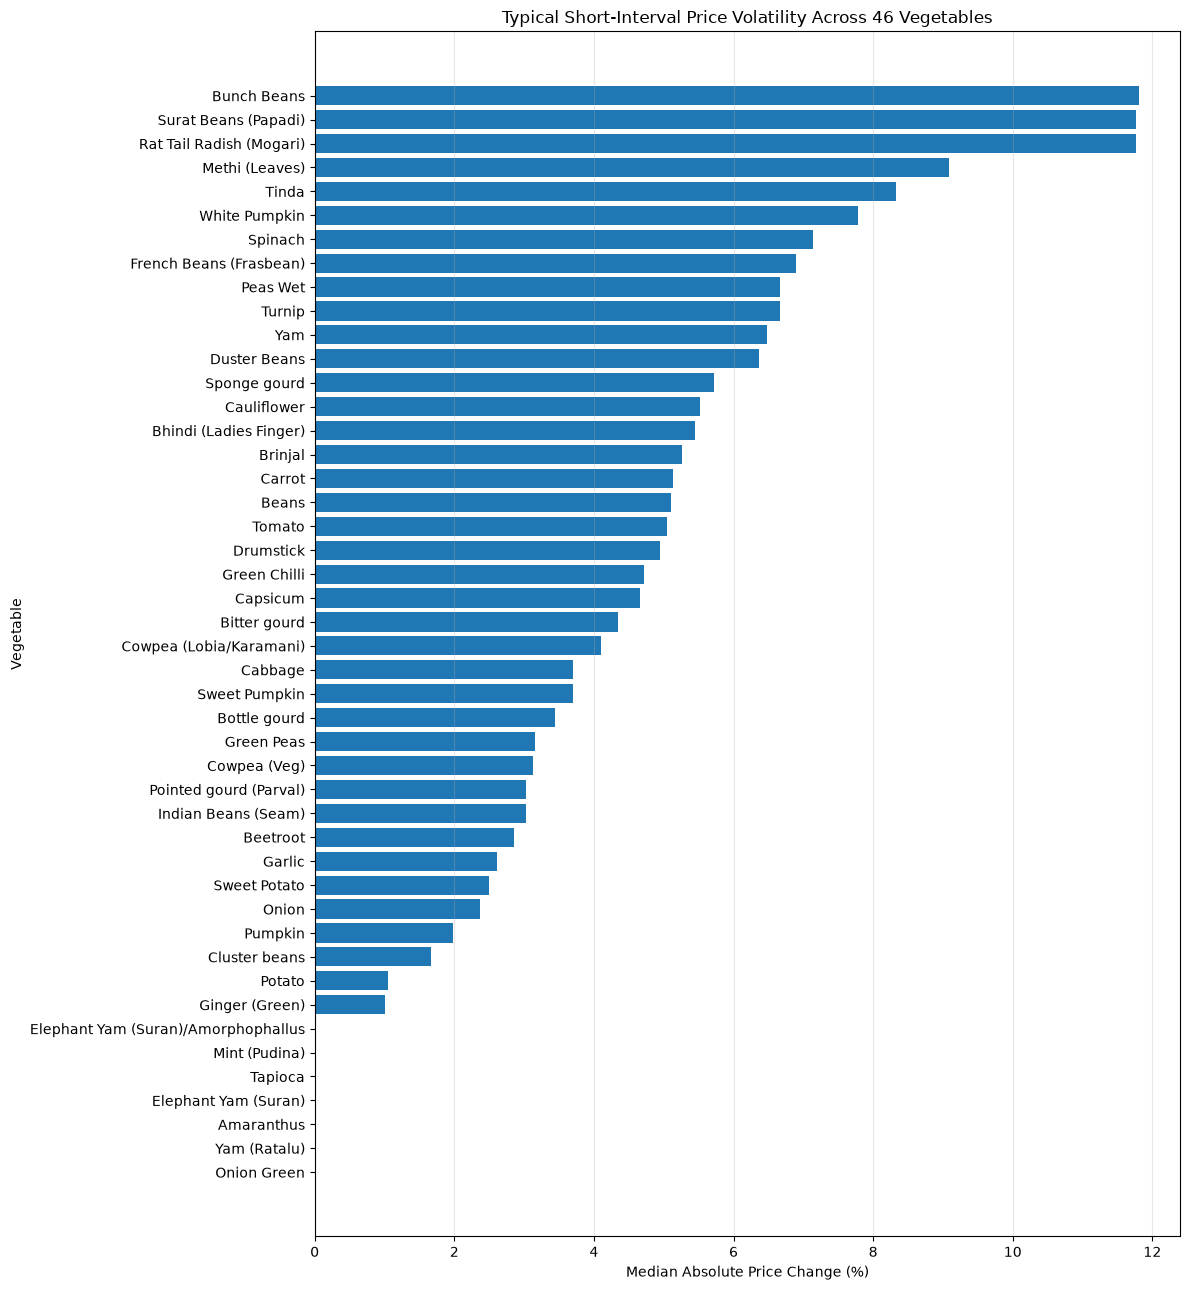

In [24]:
# Visualise median price volatility across commodities

volatility_plot = high_volatility_summary.sort_values(
    "Median_Pct_Change",
    ascending=True
)

plt.figure(figsize=(12, 13))

plt.barh(
    volatility_plot["Project_Commodity"],
    volatility_plot["Median_Pct_Change"]
)

plt.xlabel("Median Absolute Price Change (%)")
plt.ylabel("Vegetable")
plt.title("Typical Short-Interval Price Volatility Across 46 Vegetables")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
# Calculate monthly median prices for each vegetable

monthly_prices = con.execute("""
    SELECT
        Project_Commodity,
        MONTH(Parsed_Date) AS Month,
        MEDIAN(Modal_Price) AS Median_Modal_Price,
        COUNT(*) AS Record_Count
    FROM prices
    WHERE Parsed_Date BETWEEN '2015-01-01' AND '2025-10-31'
    GROUP BY
        Project_Commodity,
        MONTH(Parsed_Date)
    ORDER BY
        Project_Commodity,
        Month
""").df()

print("Monthly commodity-level observations:", len(monthly_prices))
display(monthly_prices.head(30))

Monthly commodity-level observations: 540


,Project_Commodity,Month,Median_Modal_Price,Record_Count
0,Amaranthus,1,2600.0,17140
1,Amaranthus,2,2500.0,16411
2,Amaranthus,3,2500.0,17397
3,Amaranthus,4,2500.0,16203
4,Amaranthus,5,2500.0,17486
5,Amaranthus,6,2500.0,17591
6,Amaranthus,7,2500.0,20261
7,Amaranthus,8,2524.0,20628
8,Amaranthus,9,2500.0,20665
9,Amaranthus,10,2600.0,20216


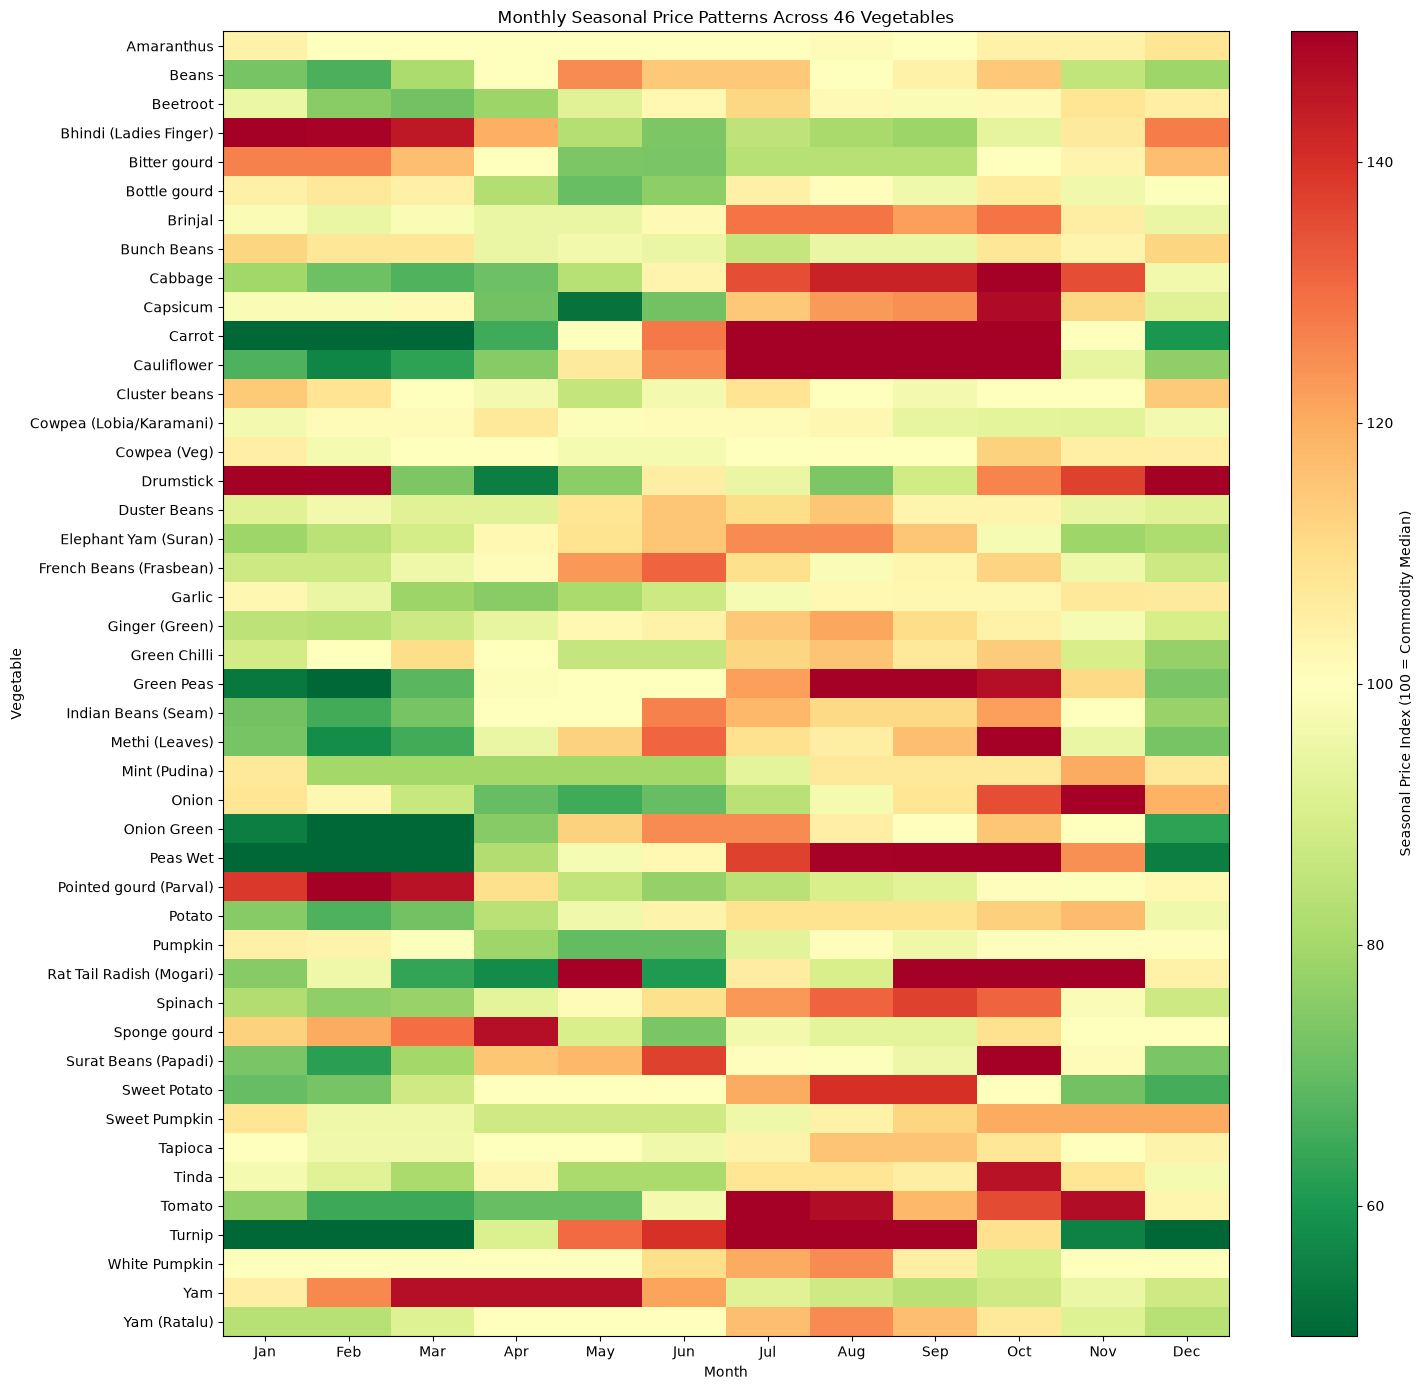

In [26]:
# Create a normalised seasonal price index

seasonal_pivot = monthly_prices.pivot(
    index="Project_Commodity",
    columns="Month",
    values="Median_Modal_Price"
)

seasonal_index = (
    seasonal_pivot
    .div(seasonal_pivot.median(axis=1), axis=0)
    * 100
)

# Plot seasonal price index heatmap

plt.figure(figsize=(15, 14))

image = plt.imshow(
    seasonal_index,
    aspect="auto",
    cmap="RdYlGn_r",
    vmin=50,
    vmax=150
)

plt.colorbar(
    image,
    label="Seasonal Price Index (100 = Commodity Median)"
)

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.yticks(
    range(len(seasonal_index.index)),
    seasonal_index.index
)

plt.xlabel("Month")
plt.ylabel("Vegetable")
plt.title("Monthly Seasonal Price Patterns Across 46 Vegetables")

plt.tight_layout()
plt.show()

In [27]:
# Calculate monthly median prices separately for each year

yearly_monthly_prices = con.execute("""
    SELECT
        Project_Commodity,
        YEAR(Parsed_Date) AS Year,
        MONTH(Parsed_Date) AS Month,
        MEDIAN(Modal_Price) AS Median_Modal_Price,
        COUNT(*) AS Record_Count
    FROM prices
    WHERE Parsed_Date BETWEEN '2015-01-01' AND '2025-10-31'
    GROUP BY
        Project_Commodity,
        YEAR(Parsed_Date),
        MONTH(Parsed_Date)
    ORDER BY
        Project_Commodity,
        Year,
        Month
""").df()

# Normalise each month's price against that commodity's median for that year

yearly_monthly_prices["Yearly_Median"] = (
    yearly_monthly_prices
    .groupby(["Project_Commodity", "Year"])["Median_Modal_Price"]
    .transform("median")
)

yearly_monthly_prices["Seasonal_Index"] = (
    yearly_monthly_prices["Median_Modal_Price"]
    / yearly_monthly_prices["Yearly_Median"] * 100
)

# Summarise how consistently each month is above or below its yearly median

seasonal_consistency = (
    yearly_monthly_prices
    .groupby(["Project_Commodity", "Month"])
    .agg(
        Years_Observed=("Year", "nunique"),
        Median_Seasonal_Index=("Seasonal_Index", "median"),
        Years_Above_100=("Seasonal_Index", lambda x: (x > 100).sum()),
        Years_Below_100=("Seasonal_Index", lambda x: (x < 100).sum())
    )
    .reset_index()
)

seasonal_consistency["Above_100_Pct"] = (
    seasonal_consistency["Years_Above_100"]
    / seasonal_consistency["Years_Observed"] * 100
).round(1)

display(seasonal_consistency.head(30).round(2))

,Project_Commodity,Month,Years_Observed,Median_Seasonal_Index,Years_Above_100,Years_Below_100,Above_100_Pct
0,Amaranthus,1,11,100.00,5,2,45.5
1,Amaranthus,2,11,100.00,2,4,18.2
2,Amaranthus,3,11,95.00,1,7,9.1
3,Amaranthus,4,11,95.00,0,8,0.0
4,Amaranthus,5,11,97.30,1,6,9.1
5,Amaranthus,6,11,100.00,3,5,27.3
6,Amaranthus,7,11,100.00,2,4,18.2
7,Amaranthus,8,11,100.00,2,1,18.2
8,Amaranthus,9,11,100.00,2,2,18.2
9,Amaranthus,10,11,100.00,3,1,27.3


In [28]:
# Calculate consistency percentages

seasonal_consistency["Below_100_Pct"] = (
    seasonal_consistency["Years_Below_100"]
    / seasonal_consistency["Years_Observed"] * 100
).round(1)

# Identify consistently expensive months

consistently_expensive = seasonal_consistency[
    (seasonal_consistency["Years_Observed"] >= 8) &
    (seasonal_consistency["Median_Seasonal_Index"] >= 110) &
    (seasonal_consistency["Above_100_Pct"] >= 70)
].sort_values(
    ["Median_Seasonal_Index", "Above_100_Pct"],
    ascending=False
)

# Identify consistently cheaper months

consistently_cheaper = seasonal_consistency[
    (seasonal_consistency["Years_Observed"] >= 8) &
    (seasonal_consistency["Median_Seasonal_Index"] <= 90) &
    (seasonal_consistency["Below_100_Pct"] >= 70)
].sort_values(
    ["Median_Seasonal_Index", "Below_100_Pct"]
)

print("Consistently expensive commodity-month combinations:")
display(consistently_expensive.round(2))

print("Consistently cheaper commodity-month combinations:")
display(consistently_cheaper.round(2))

Consistently expensive commodity-month combinations:


,Project_Commodity,Month,Years_Observed,Median_Seasonal_Index,Years_Above_100,Years_Below_100,Above_100_Pct,Below_100_Pct
180,Drumstick,1,11,233.77,11,0,100.0,0.0
394,Rat Tail Radish (Mogari),11,8,221.24,8,0,100.0,0.0
191,Drumstick,12,10,217.46,9,1,90.0,10.0
345,Peas Wet,10,11,191.18,11,0,100.0,0.0
349,Pointed gourd (Parval),2,11,186.67,11,0,100.0,0.0
...,...,...,...,...,...,...,...,...
259,Green Chilli,8,11,110.85,9,2,81.8,18.2
261,Green Chilli,10,11,110.85,9,2,81.8,18.2
225,French Beans (Frasbean),10,11,110.34,11,0,100.0,0.0
366,Potato,7,11,110.20,10,1,90.9,9.1


Consistently cheaper commodity-month combinations:


,Project_Commodity,Month,Years_Observed,Median_Seasonal_Index,Years_Above_100,Years_Below_100,Above_100_Pct,Below_100_Pct
265,Green Peas,2,11,40.40,0,11,0.0,100.0
121,Carrot,2,11,41.00,0,11,0.0,100.0
337,Peas Wet,2,11,42.86,0,11,0.0,100.0
338,Peas Wet,3,11,43.04,0,11,0.0,100.0
264,Green Peas,1,11,43.24,0,11,0.0,100.0
...,...,...,...,...,...,...,...,...
412,Sponge gourd,5,11,89.74,1,10,9.1,90.9
529,Yam (Ratalu),2,11,89.80,2,8,18.2,72.7
91,Bunch Beans,8,11,90.00,0,10,0.0,90.9
473,Tinda,6,11,90.00,0,10,0.0,90.9


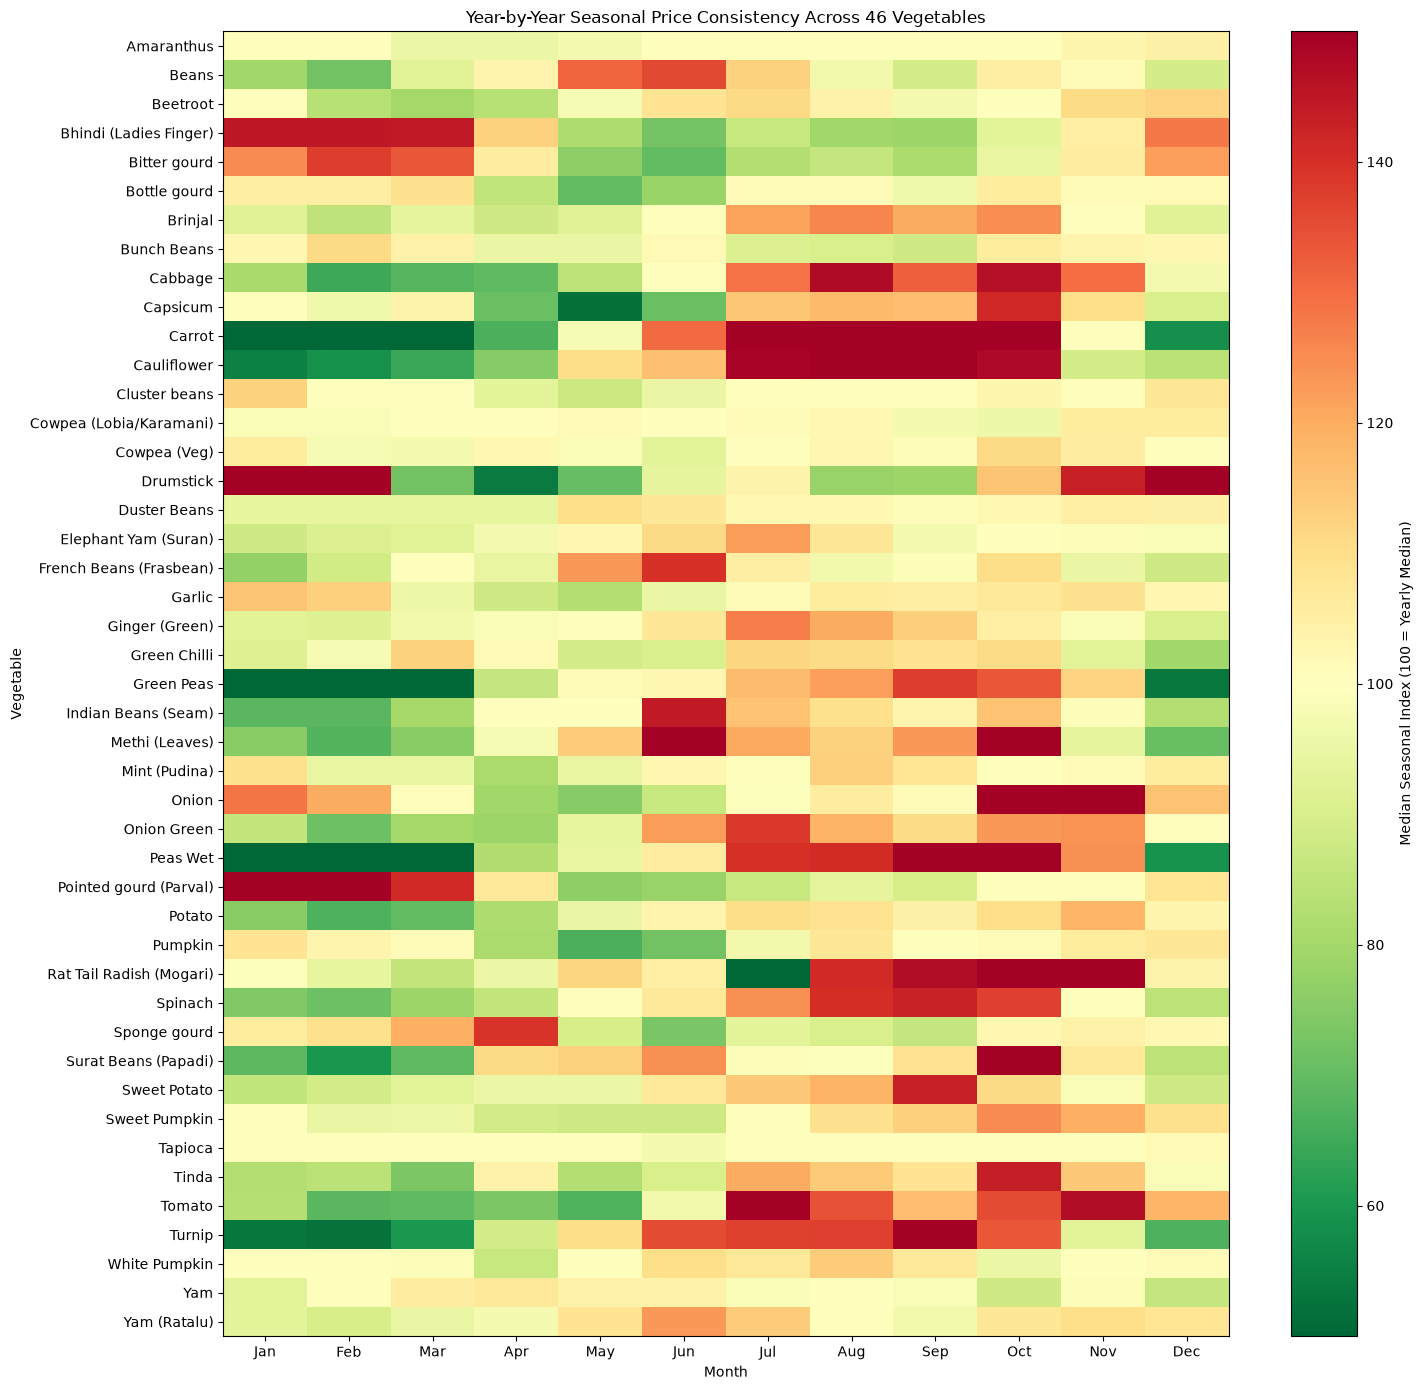

In [29]:
# Create a commodity-month seasonal consistency matrix

seasonal_consistency_pivot = seasonal_consistency.pivot(
    index="Project_Commodity",
    columns="Month",
    values="Median_Seasonal_Index"
)

seasonal_consistency_pivot = seasonal_consistency_pivot.reindex(
    columns=range(1, 13)
)

plt.figure(figsize=(15, 14))

image = plt.imshow(
    seasonal_consistency_pivot,
    aspect="auto",
    cmap="RdYlGn_r",
    vmin=50,
    vmax=150
)

plt.colorbar(
    image,
    label="Median Seasonal Index (100 = Yearly Median)"
)

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.yticks(
    range(len(seasonal_consistency_pivot.index)),
    seasonal_consistency_pivot.index
)

plt.xlabel("Month")
plt.ylabel("Vegetable")
plt.title("Year-by-Year Seasonal Price Consistency Across 46 Vegetables")

plt.tight_layout()
plt.show()

In [30]:
# Calculate consecutive reporting gaps for all market-level series

reporting_gaps = con.execute("""
    WITH dated_series AS (
        SELECT
            State,
            District,
            Market,
            Project_Commodity,
            Variety,
            Grade,
            Parsed_Date,
            LAG(Parsed_Date) OVER (
                PARTITION BY
                    State, District, Market,
                    Project_Commodity, Variety, Grade
                ORDER BY Parsed_Date
            ) AS Previous_Date
        FROM prices
    )
    SELECT
        State,
        District,
        Market,
        Project_Commodity,
        Variety,
        Grade,
        Previous_Date,
        Parsed_Date AS Current_Date,
        DATE_DIFF('day', Previous_Date, Parsed_Date) AS Gap_Days
    FROM dated_series
    WHERE Previous_Date IS NOT NULL
""").df()

print("Consecutive reporting intervals:", len(reporting_gaps))
display(reporting_gaps["Gap_Days"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Consecutive reporting intervals: 30257461


count    3.025746e+07
mean     3.588184e+00
std      4.819214e+01
min      1.000000e+00
50%      1.000000e+00
75%      2.000000e+00
90%      3.000000e+00
95%      5.000000e+00
99%      2.300000e+01
max      8.315000e+03
Name: Gap_Days, dtype: float64

In [31]:
# Summarise reporting gaps by commodity

gap_summary = (
    reporting_gaps
    .groupby("Project_Commodity")
    .agg(
        Total_Intervals=("Gap_Days", "count"),
        Median_Gap_Days=("Gap_Days", "median"),
        P90_Gap_Days=("Gap_Days", lambda x: x.quantile(0.90)),
        P95_Gap_Days=("Gap_Days", lambda x: x.quantile(0.95)),
        Maximum_Gap_Days=("Gap_Days", "max"),
        Gaps_Above_7_Days=("Gap_Days", lambda x: (x > 7).sum()),
        Gaps_Above_30_Days=("Gap_Days", lambda x: (x > 30).sum())
    )
    .reset_index()
)

gap_summary["Pct_Gaps_Above_7_Days"] = (
    gap_summary["Gaps_Above_7_Days"]
    / gap_summary["Total_Intervals"] * 100
).round(2)

gap_summary["Pct_Gaps_Above_30_Days"] = (
    gap_summary["Gaps_Above_30_Days"]
    / gap_summary["Total_Intervals"] * 100
).round(2)

gap_summary = gap_summary.sort_values(
    "Pct_Gaps_Above_30_Days",
    ascending=False
)

display(gap_summary.round(2))

,Project_Commodity,Total_Intervals,Median_Gap_Days,P90_Gap_Days,P95_Gap_Days,Maximum_Gap_Days,Gaps_Above_7_Days,Gaps_Above_30_Days,Pct_Gaps_Above_7_Days,Pct_Gaps_Above_30_Days
13,Cowpea (Lobia/Karamani),71959,2.0,11.0,28.0,7401,9252,3337,12.86,4.64
43,White Pumpkin,12252,2.0,8.0,21.0,4331,1332,493,10.87,4.02
33,Rat Tail Radish (Mogari),4337,1.0,4.0,9.0,3384,243,130,5.60,3.00
40,Tinda,158087,1.0,4.0,10.0,5845,9563,4231,6.05,2.68
7,Bunch Beans,21316,2.0,10.0,21.0,4271,3021,542,14.17,2.54
42,Turnip,63310,1.0,5.0,10.0,4353,3962,1590,6.26,2.51
37,Sweet Potato,153594,1.0,5.0,11.0,5686,9948,3814,6.48,2.48
23,Green Peas,145244,1.0,5.0,10.0,7916,9191,3129,6.33,2.15
44,Yam,10798,1.0,6.0,11.0,3762,734,220,6.80,2.04
25,Methi (Leaves),205812,1.0,3.0,7.0,6937,8852,3250,4.30,1.58


In [32]:
# Identify market-level series with substantial reporting interruptions

series_gap_summary = (
    reporting_gaps
    .groupby([
        "State",
        "District",
        "Market",
        "Project_Commodity",
        "Variety",
        "Grade"
    ])
    .agg(
        Total_Intervals=("Gap_Days", "count"),
        Median_Gap_Days=("Gap_Days", "median"),
        P90_Gap_Days=("Gap_Days", lambda x: x.quantile(0.90)),
        Maximum_Gap_Days=("Gap_Days", "max"),
        Gaps_Above_30_Days=("Gap_Days", lambda x: (x > 30).sum())
    )
    .reset_index()
)

series_gap_summary["Pct_Gaps_Above_30_Days"] = (
    series_gap_summary["Gaps_Above_30_Days"]
    / series_gap_summary["Total_Intervals"] * 100
).round(2)

# Exclude very short series to avoid misleading percentages
interrupted_series = (
    series_gap_summary[
        series_gap_summary["Total_Intervals"] >= 100
    ]
    .sort_values(
        ["Pct_Gaps_Above_30_Days", "Maximum_Gap_Days"],
        ascending=False
    )
)

print("Series with at least 100 reporting intervals:",
      len(interrupted_series))

display(interrupted_series.head(25).round(2))

Series with at least 100 reporting intervals: 30046


,State,District,Market,Project_Commodity,Variety,Grade,Total_Intervals,Median_Gap_Days,P90_Gap_Days,Maximum_Gap_Days,Gaps_Above_30_Days,Pct_Gaps_Above_30_Days
42516,Punjab,kapurthala,Dhilwan,Potato,Other,FAQ,105,31.0,91.2,1095,58,55.24
16811,Karnataka,Kolar,Malur,Green Chilli,Green Chilly,FAQ,102,25.0,158.8,1201,44,43.14
16101,Karnataka,Hassan,Hassan,Green Peas,Green Peas,FAQ,146,26.5,105.5,792,62,42.47
29394,Maharashtra,Dharashiv (Usmanabad),Dharashiv,Sweet Potato,Other,FAQ,121,2.0,146.0,812,45,37.19
29512,Maharashtra,Jalgaon,Amalner,Cowpea (Lobia/Karamani),Other,FAQ,112,14.0,141.8,594,40,35.71
29653,Maharashtra,Jalgaon,Jalgaon,Sweet Potato,Other,FAQ,119,5.0,119.2,1670,41,34.45
33576,Odisha,Angul,Angaura,Garlic,Other,FAQ,102,14.0,103.8,644,31,30.39
4944,Chattisgarh,Raigarh,Raigarh,Green Chilli,Other,FAQ,174,28.0,32.0,122,52,29.89
28816,Maharashtra,Ahmednagar,Rahata,Sweet Potato,Other,FAQ,115,2.0,127.2,381,34,29.57
42933,Rajasthan,Bundi,Bundi,Green Peas,Other,FAQ,122,11.5,94.8,2083,36,29.51


In [34]:
import pandas as pd

# Combine time-series coverage, reporting gaps and price-change statistics
suitability = series_coverage.merge(
    series_gap_summary,
    on=[
        "State",
        "District",
        "Market",
        "Project_Commodity",
        "Variety",
        "Grade",
    ],
    suffixes=("", "_Gap"),
)

suitability = suitability.merge(
    price_change_stats[
        [
            "State",
            "District",
            "Market",
            "Project_Commodity",
            "Variety",
            "Grade",
            "Short_Interval_Changes",
            "Median_Absolute_Pct_Change",
            "P90_Absolute_Pct_Change",
        ]
    ],
    on=[
        "State",
        "District",
        "Market",
        "Project_Commodity",
        "Variety",
        "Grade",
    ],
    how="left",
    suffixes=("", "_PriceStats"),
)

# Calculate recency relative to the final date in the dataset (ensuring proper datetime type)
dataset_end = pd.to_datetime(
    con.execute("""
    SELECT MAX(Parsed_Date) FROM prices
""").fetchone()[0]
)

suitability["Days_Before_Dataset_End"] = (
    dataset_end - pd.to_datetime(suitability["Last_Date"])
).dt.days

# Apply transparent preliminary screening criteria
suitability["Pass_Observation_Count"] = suitability["Observation_Count"] >= 500

suitability["Pass_Recency"] = suitability["Days_Before_Dataset_End"] <= 180

suitability["Pass_Reporting_Gaps"] = suitability["P90_Gap_Days"] <= 7

suitability["Pass_Long_Gap_Rate"] = suitability["Pct_Gaps_Above_30_Days"] <= 5

suitability["Pass_Price_Changes"] = (
    suitability["Short_Interval_Changes"].fillna(0) >= 100
)

criteria_columns = [
    "Pass_Observation_Count",
    "Pass_Recency",
    "Pass_Reporting_Gaps",
    "Pass_Long_Gap_Rate",
    "Pass_Price_Changes",
]

suitability["Criteria_Passed"] = suitability[criteria_columns].sum(axis=1)

# Summarise how many series pass each criterion
criterion_summary = pd.DataFrame({
    "Criterion": criteria_columns,
    "Series_Passing": [
        suitability[column].sum() for column in criteria_columns
    ],
})

criterion_summary["Passing_Percentage"] = (
    criterion_summary["Series_Passing"] / len(suitability) * 100
).round(2)

print("Total assessed series:", len(suitability))
print("Dataset end date:", dataset_end)

display(criterion_summary)

print("\nSeries passing all five criteria:")
print((suitability["Criteria_Passed"] == 5).sum())

display(
    suitability[suitability["Criteria_Passed"] == 5]
    .sort_values(
        ["Observation_Count", "Short_Interval_Changes"], ascending=False
    )[
        [
            "State",
            "District",
            "Market",
            "Project_Commodity",
            "Variety",
            "Grade",
            "Observation_Count",
            "Days_Before_Dataset_End",
            "P90_Gap_Days",
            "Pct_Gaps_Above_30_Days",
            "Short_Interval_Changes",
            "Criteria_Passed",
        ]
    ]
    .head(20)
)

Total assessed series: 70233
Dataset end date: 2026-04-20 00:00:00


,Criterion,Series_Passing,Passing_Percentage
0,Pass_Observation_Count,14217,20.24
1,Pass_Recency,30196,42.99
2,Pass_Reporting_Gaps,42651,60.73
3,Pass_Long_Gap_Rate,55569,79.12
4,Pass_Price_Changes,27897,39.72



Series passing all five criteria:
5836


,State,District,Market,Project_Commodity,Variety,Grade,Observation_Count,Days_Before_Dataset_End,P90_Gap_Days,Pct_Gaps_Above_30_Days,Short_Interval_Changes,Criteria_Passed
0,West Bengal,Hooghly,Champadanga,Potato,Jyoti,FAQ,7181,166,1.0,0.17,7122.0,5
1,Uttar Pradesh,Unnao,Unnao,Potato,Desi,FAQ,6809,167,2.0,0.03,6710.0,5
2,West Bengal,Purba Bardhaman,Burdwan,Potato,Jyoti,FAQ,6748,168,2.0,0.09,6613.0,5
3,Uttar Pradesh,Unnao,Unnao,Onion,Red,FAQ,6651,167,2.0,0.05,6543.0,5
4,Uttar Pradesh,Bareilly,Bareilly,Onion,Red,FAQ,6517,167,1.0,0.05,6469.0,5
6,Punjab,Bhatinda,Raman,Potato,Other,FAQ,6285,168,2.0,0.13,6170.0,5
7,Gujarat,Ahmedabad,Ahmedabad,Bhindi (Ladies Finger),Other,FAQ,6224,167,2.0,0.10,6103.0,5
10,Gujarat,Ahmedabad,Ahmedabad,Green Chilli,Other,FAQ,6175,167,2.0,0.10,6042.0,5
11,Gujarat,Ahmedabad,Ahmedabad,Bitter gourd,Other,FAQ,6153,167,2.0,0.11,6021.0,5
12,Punjab,Bhatinda,Raman,Onion,Other,FAQ,6123,168,2.0,0.15,5979.0,5


Total commodities assessed: 46
Total series passing all criteria: 5836


,Project_Commodity,Total_Series,Series_Passing_All,Series_Passing_4_or_More,Average_Criteria_Passed,Passing_All_Pct
6,Brinjal,4368,530,1330,2.61,12.13
31,Potato,6313,523,1718,2.43,8.28
27,Onion,6433,498,1732,2.31,7.74
41,Tomato,5688,456,1595,2.47,8.02
22,Green Chilli,3563,441,1125,2.62,12.38
3,Bhindi (Ladies Finger),3065,367,1039,2.74,11.97
11,Cauliflower,3340,333,1019,2.65,9.97
5,Bottle gourd,2420,310,800,2.70,12.81
32,Pumpkin,2459,296,761,2.60,12.04
8,Cabbage,3143,294,896,2.53,9.35


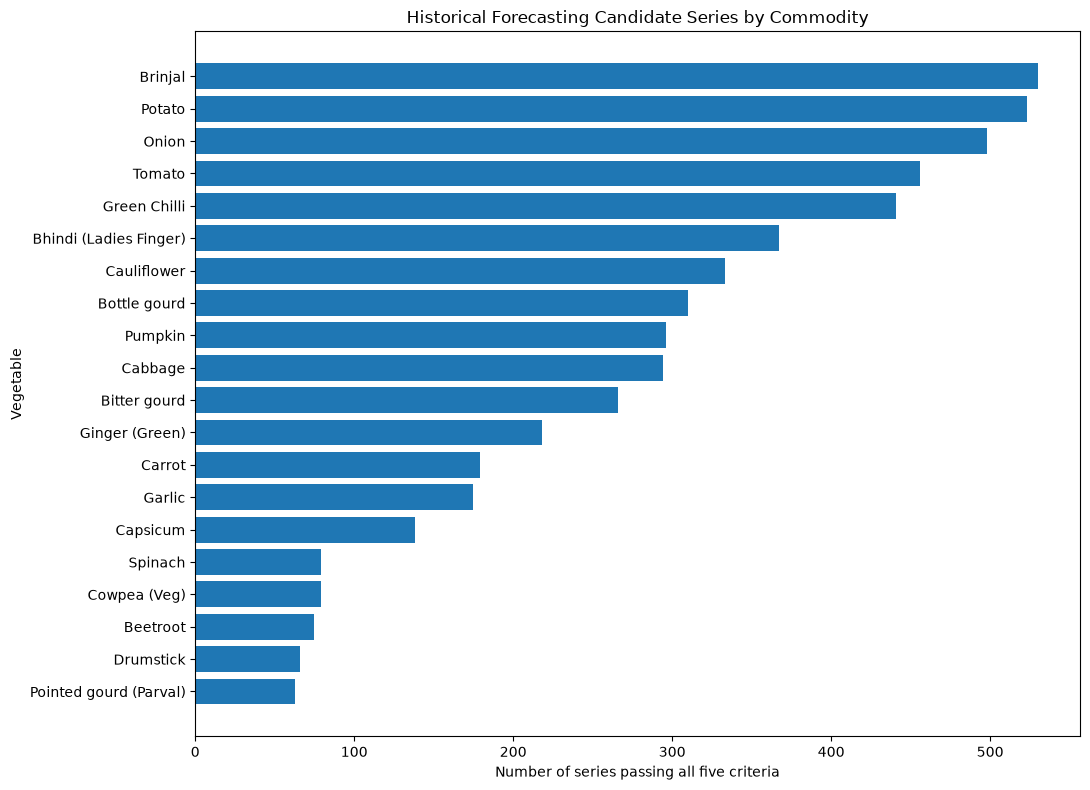

In [35]:
# Summarise preliminary forecasting suitability by commodity

commodity_suitability = (
    suitability
    .groupby("Project_Commodity")
    .agg(
        Total_Series=("Criteria_Passed", "count"),
        Series_Passing_All=("Criteria_Passed", lambda x: (x == 5).sum()),
        Series_Passing_4_or_More=("Criteria_Passed", lambda x: (x >= 4).sum()),
        Average_Criteria_Passed=("Criteria_Passed", "mean")
    )
    .reset_index()
)

commodity_suitability["Passing_All_Pct"] = (
    commodity_suitability["Series_Passing_All"]
    / commodity_suitability["Total_Series"] * 100
).round(2)

commodity_suitability = commodity_suitability.sort_values(
    "Series_Passing_All",
    ascending=False
)

print("Total commodities assessed:", len(commodity_suitability))
print(
    "Total series passing all criteria:",
    commodity_suitability["Series_Passing_All"].sum()
)

display(commodity_suitability.round(2))

# Visualise commodities with the most qualifying series

plot_data = commodity_suitability.head(20).sort_values(
    "Series_Passing_All"
)

plt.figure(figsize=(11, 8))

plt.barh(
    plot_data["Project_Commodity"],
    plot_data["Series_Passing_All"]
)

plt.xlabel("Number of series passing all five criteria")
plt.ylabel("Vegetable")
plt.title("Historical Forecasting Candidate Series by Commodity")
plt.tight_layout()
plt.show()

## 10. Time-Series Suitability Assessment and Key Findings

### 10.1 Reporting Continuity

Across 30,257,461 consecutive reporting intervals:

- Median reporting gap was 1 day.
- 75% of intervals were 2 days or less.
- 90% were 3 days or less.
- 99% were 23 days or less.

Although most observations were closely spaced, individual market-level series showed substantial interruptions. Reporting continuity therefore needs to be assessed at the individual series level.

### 10.2 Historical Price Behaviour

Price-change analysis revealed considerable variation in volatility across commodities and markets. Extreme percentage changes were observed in some series, indicating the need for further anomaly investigation before model training.

Seasonal analysis identified recurring historical monthly price patterns across several vegetables. However, these patterns are descriptive and do not establish guaranteed future price movements.

### 10.3 Preliminary Forecasting Suitability

A preliminary screening framework evaluated market-level series using five criteria:

1. At least 500 observations.
2. Last observation within 180 days of the dataset end date.
3. 90th-percentile reporting gap no greater than 7 days.
4. No more than 5% of reporting intervals exceeding 30 days.
5. At least 100 usable short-interval price changes.

Out of 78,858 identified market-level series, 8,625 single-observation series could not be evaluated for reporting gaps. The remaining 70,233 series were assessed.

A total of 5,836 series passed all five criteria, representing approximately 8.31% of assessed series.

Brinjal, Potato, Onion, Tomato and Green Chilli contributed the largest numbers of qualifying series.

These criteria provide an initial screening framework, not a guarantee of predictive performance. Final candidate selection must also consider chronological validation and model performance.

### 10.4 Data Limitations

- The dataset ends on 20 April 2026 and cannot support claims of live market forecasting in November 2026.
- Reporting activity declined substantially from November 2025 onward.
- Historical reporting gaps may reflect market schedules, seasonal availability, inactivity or data interruptions.
- Extreme price changes require further investigation and should not be automatically removed.
- Historical seasonal patterns do not establish causal relationships or guarantee future prices.

### 10.5 Conclusion

The expanded dataset provides substantial historical coverage across 46 selected vegetables and thousands of agricultural markets.

However, the analysis demonstrates that data availability, reporting continuity, recency and price behaviour vary considerably between individual market-level series.

The 5,836 qualifying series provide a starting pool for retrospective forecasting experiments. Subsequent modelling will use chronological validation and baseline comparisons to determine which series produce sufficiently reliable forecasts.

The findings support evidence-based forecasting-series selection rather than applying forecasting models indiscriminately across all commodities.

In [38]:
# Save time-series suitability results for Notebook 03

suitability_path = PROCESSED_DIR / "market_series_suitability.parquet"
summary_path = PROCESSED_DIR / "commodity_suitability_summary.csv"

suitability.to_parquet(suitability_path, index=False)
commodity_suitability.to_csv(summary_path, index=False)

preliminary_candidates = suitability[
    suitability["Criteria_Passed"] == 5
]

print(f"Saved: {suitability_path}")
print(f"Saved: {summary_path}")
print(f"Total series assessed: {len(suitability):,}")
print(f"Preliminary suitable series: {len(preliminary_candidates):,}")

Saved: c:\Users\Lenovo\Documents\GrittingCode\MandiMitra\data\processed\market_series_suitability.parquet
Saved: c:\Users\Lenovo\Documents\GrittingCode\MandiMitra\data\processed\commodity_suitability_summary.csv
Total series assessed: 70,233
Preliminary suitable series: 5,836
